# LIME

How faithfully can a local linear model mimic a random forest near one concrete recipe? LIME weights synthetic neighbours by proximity to the chosen observation.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Local surrogate

The perturbation model uses training scales. Coefficients therefore describe a one-standard-deviation change in a surrogate input.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from gallery.tabular import concrete_split

import pandas as pd
from lime.lime_tabular import LimeTabularExplainer

## Held-out performance

The forest and the split match the SHAP example.

In [3]:
X, X_test, y, y_test, groups = concrete_split()
forest = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=3, max_features=0.85, random_state=17, n_jobs=1
)
forest.fit(X, y)
prediction = forest.predict(X_test)
print(
    f"Held-out MAE {mean_absolute_error(y_test,prediction):.2f} MPa | RMSE {root_mean_squared_error(y_test,prediction):.2f} MPa | R² {r2_score(y_test,prediction):.3f}"
)

Held-out MAE 5.45 MPa | RMSE 7.88 MPa | R² 0.791


## Check fidelity and repeatability

Three perturbation seeds explain the same preselected test row. The score is the weighted local R² on the sampled neighbourhood.

Seed 17: local R² 0.768, absolute error at recipe 1.26 MPa
Seed 29: local R² 0.765, absolute error at recipe 1.25 MPa
Seed 53: local R² 0.769, absolute error at recipe 1.38 MPa
Mean top-three Jaccard agreement: 1.000
Forest prediction: 42.02 MPa | Measured: 44.30 MPa


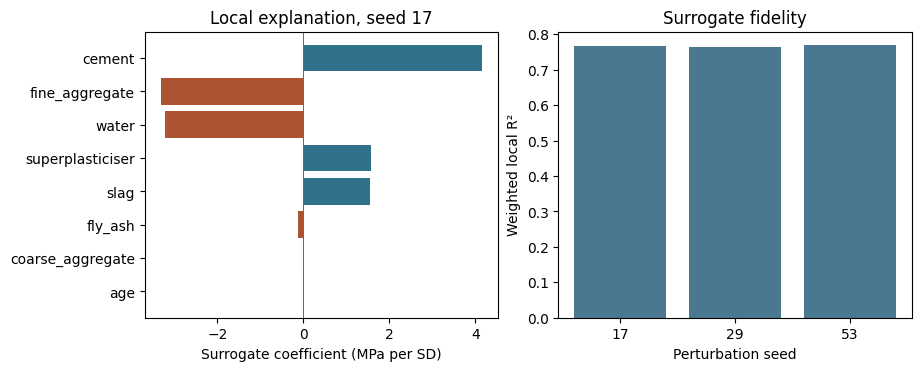

In [4]:
row = X_test.iloc[0].to_numpy()


def predict_rows(array):
    return forest.predict(pd.DataFrame(array, columns=X.columns))


weights = []
scores = []
errors = []
for seed in (17, 29, 53):
    lime = LimeTabularExplainer(
        X.to_numpy(),
        feature_names=list(X.columns),
        mode="regression",
        discretize_continuous=False,
        sample_around_instance=True,
        random_state=seed,
    )
    result = lime.explain_instance(row, predict_rows, num_features=X.shape[1], num_samples=3500)
    coeff = np.zeros(X.shape[1])
    for index, weight in result.local_exp[1]:
        coeff[index] = weight
    weights.append(coeff)
    scores.append(result.score)
    errors.append(abs(float(np.asarray(result.local_pred).item()) - prediction[0]))
    print(f"Seed {seed}: local R² {scores[-1]:.3f}, absolute error at recipe {errors[-1]:.2f} MPa")
weights = np.array(weights)
top = [set(np.argsort(abs(w))[-3:]) for w in weights]
print(
    f"Mean top-three Jaccard agreement: {np.mean([len(top[i]&top[j])/len(top[i]|top[j]) for i,j in [(0,1),(0,2),(1,2)]]):.3f}"
)
print(f"Forest prediction: {prediction[0]:.2f} MPa | Measured: {y_test.iloc[0]:.2f} MPa")
fig, (a, b) = plt.subplots(1, 2, figsize=(9.1, 3.6), constrained_layout=True)
order = np.argsort(abs(weights[0]))
a.barh(
    np.array(X.columns)[order],
    weights[0, order],
    color=np.where(weights[0, order] > 0, "#30728b", "#ac5431"),
)
a.axvline(0, color="0.4", lw=0.7)
a.set(xlabel="Surrogate coefficient (MPa per SD)", title="Local explanation, seed 17")
b.bar(["17", "29", "53"], scores, color="#4b7891")
b.set(xlabel="Perturbation seed", ylabel="Weighted local R²", title="Surrogate fidelity")
plt.show()

## Reading the result

Read the local R² and the pointwise error together. Perturbing ingredients independently can create unrealistic mixes, even if the surrogate is stable across seeds.

## References

[Ribeiro, Singh and Guestrin, “Why Should I Trust You?” (2016)](https://arxiv.org/abs/1602.04938)

[LIME, tabular explainer](https://lime-ml.readthedocs.io/en/latest/lime.html#module-lime.lime_tabular)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)